In [125]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [126]:
def build_distribution(plot_data):
    
    for title, data in plot_data.items(): 
        
        plt.figure(figsize=(12, 5))
        plt.bar(data.index.astype(str), data.values)
        plt.title(title)
        plt.xticks(rotation=45)
        plt.show()
    
def build_nulls(plot_data):
    plt.figure(figsize=(12, 6))
    plt.title('Пропуски')
    sns.heatmap(plot_data.isna(), cbar=False, yticklabels=False)
    plt.show()

def eda_report(data_frame):
    
    data_frame = pd.concat([data_frame, data_frame['dialogue'].str.len()], axis=1)
    
    data_frame.columns = ['id', 'dialogue', 'summary', 'topic', 'dialogue_len']
    
    topic_count = data_frame.groupby('topic')['dialogue_len'].size().sort_values(ascending=False)[:20]
    total_topics = data_frame.groupby('topic').size()
    dialogue_len_dist_top_20 = data_frame.groupby('topic')['dialogue_len'].median().sort_values(ascending=False)[:20]
    dialogue_len_dist_top_20_bottom = data_frame.groupby('topic')['dialogue_len'].median().sort_values(ascending=False)[-20:-1:1]
    
    plot_data = {
        'Количество топиков': topic_count, 
        'Топ 20 топиков по длине': dialogue_len_dist_top_20, 
        'Топ 20 самих коротких топиков': dialogue_len_dist_top_20_bottom,
    }
    
    build_distribution(plot_data)
    build_nulls(data_frame)
    
    
    print(f'Общее количество уникальных топиков: {total_topics.shape}')
    print(f'Размер: {data_frame.shape}')
    

<hr>

train

In [127]:
df_train = pd.read_csv('../data/train.csv/train.csv')

In [128]:
df_train.head()

,id,dialogue,summary,topic
0,train_0,"#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. ...","Mr. Smith's getting a check-up, and Doctor Haw...",get a check-up
1,train_1,"#Person1#: Hello Mrs. Parker, how have you bee...",Mrs Parker takes Ricky for his vaccines. Dr. P...,vaccines
2,train_2,"#Person1#: Excuse me, did you see a set of key...",#Person1#'s looking for a set of keys and asks...,find keys
3,train_3,#Person1#: Why didn't you tell me you had a gi...,#Person1#'s angry because #Person2# didn't tel...,have a girlfriend
4,train_4,"#Person1#: Watsup, ladies! Y'll looking'fine t...",Malik invites Nikki to dance. Nikki agrees if ...,dance


In [129]:
df_train.loc[0, 'summary']

"Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking."

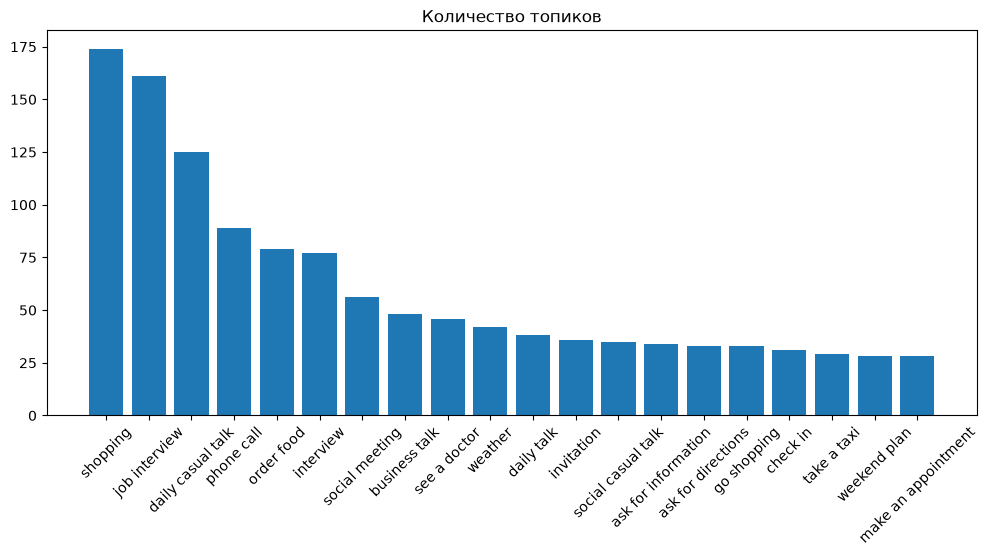

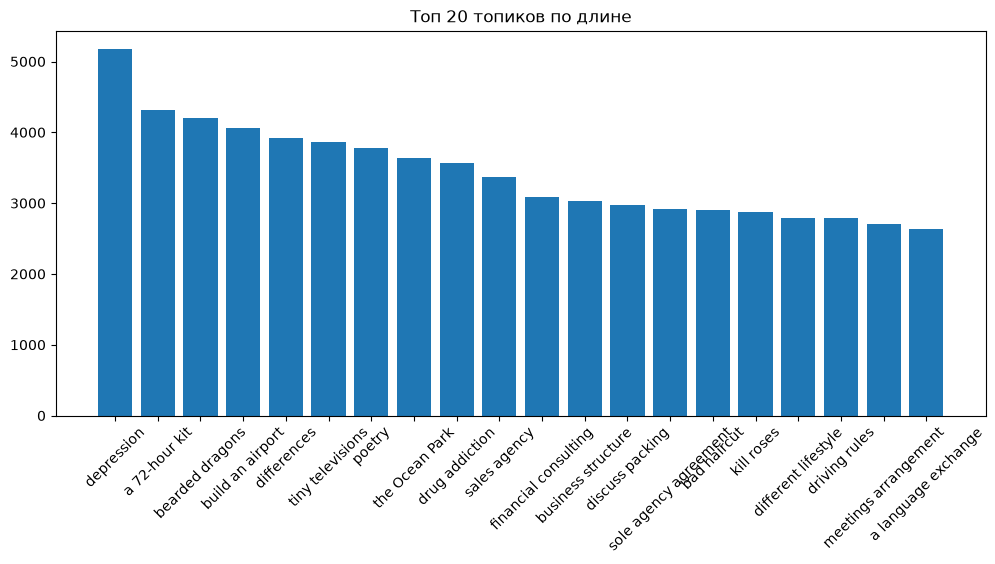

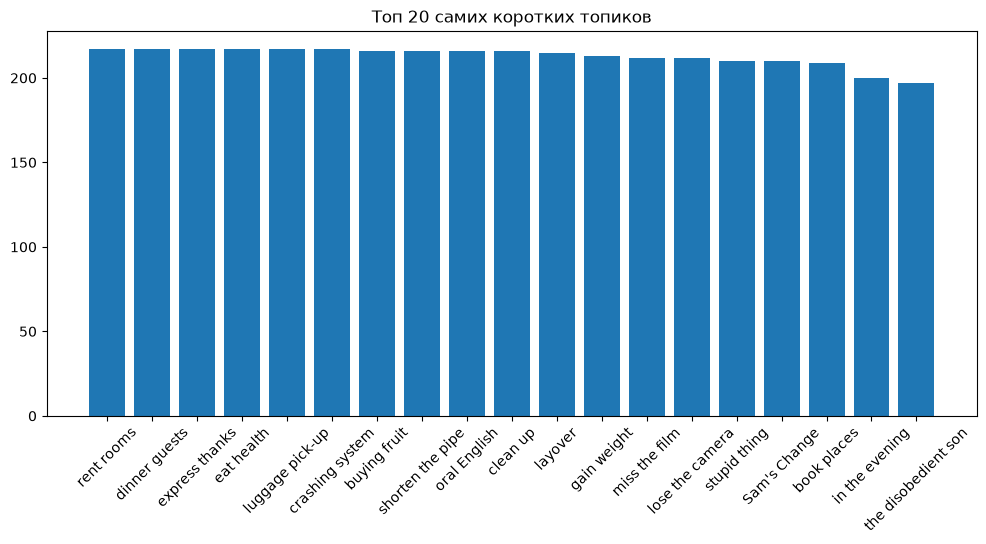

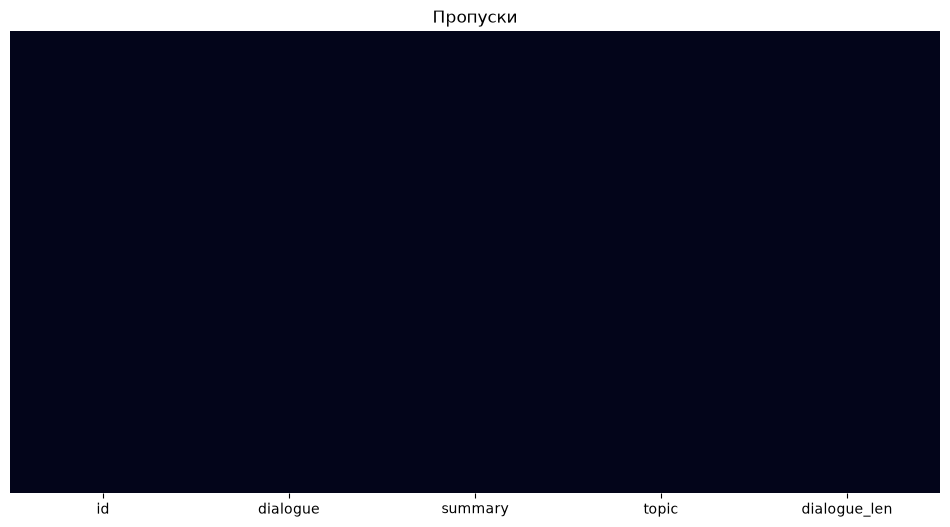

Общее количество уникальных топиков: (7434,)
Размер: (12460, 5)


In [130]:
eda_report(df_train)

<hr>

test 

In [131]:
df_test = pd.read_csv('../data/test.csv/test.csv')

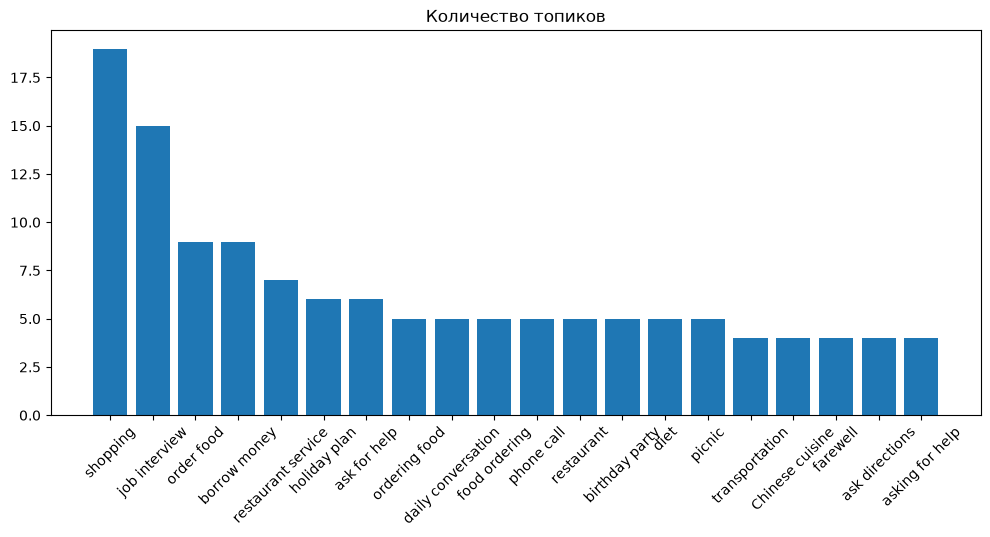

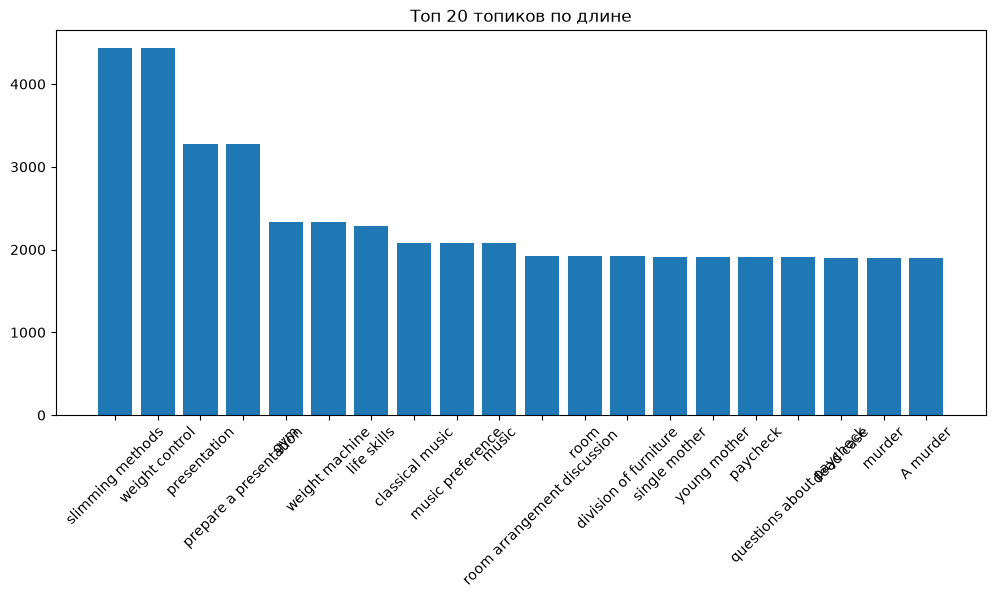

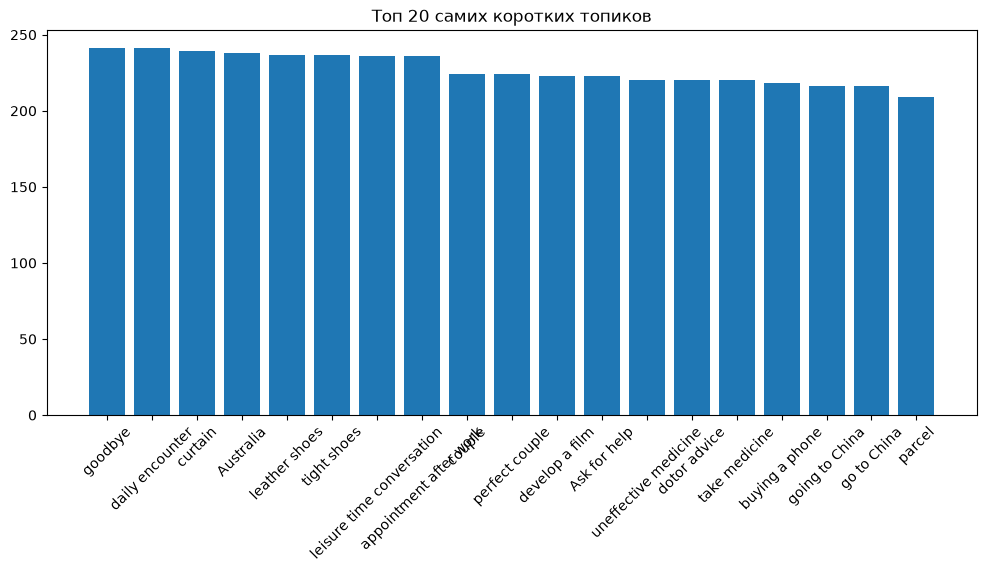

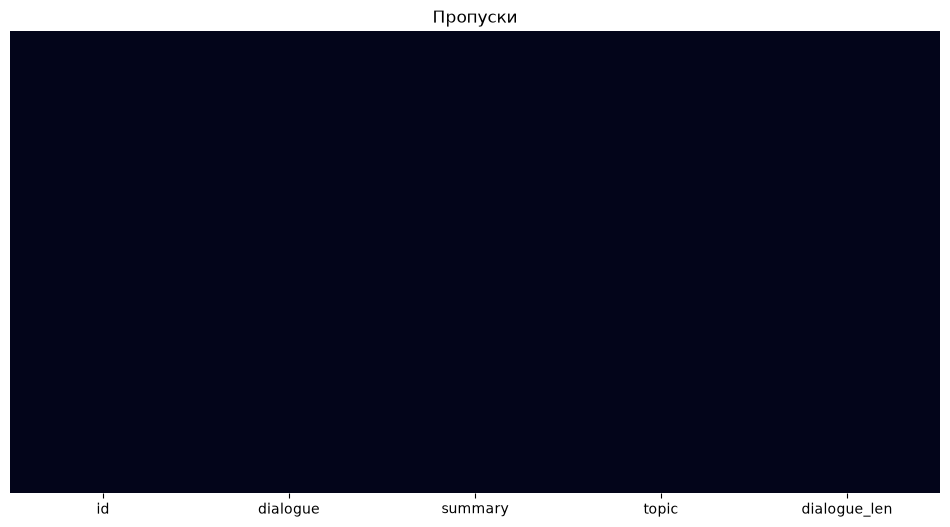

Общее количество уникальных топиков: (1154,)
Размер: (1500, 5)


In [132]:
eda_report(df_test)

<hr>

validation

In [133]:
df_validation = pd.read_csv('../data/validation.csv')

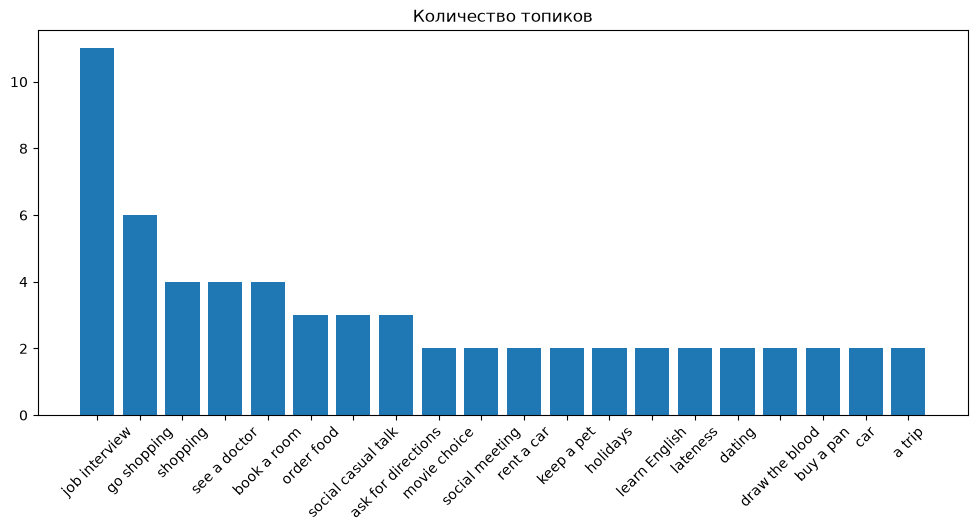

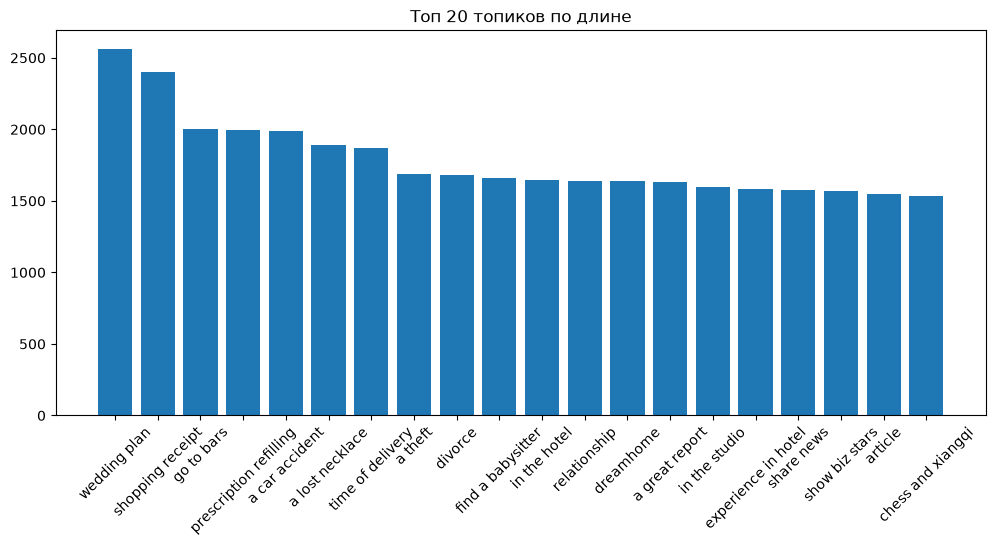

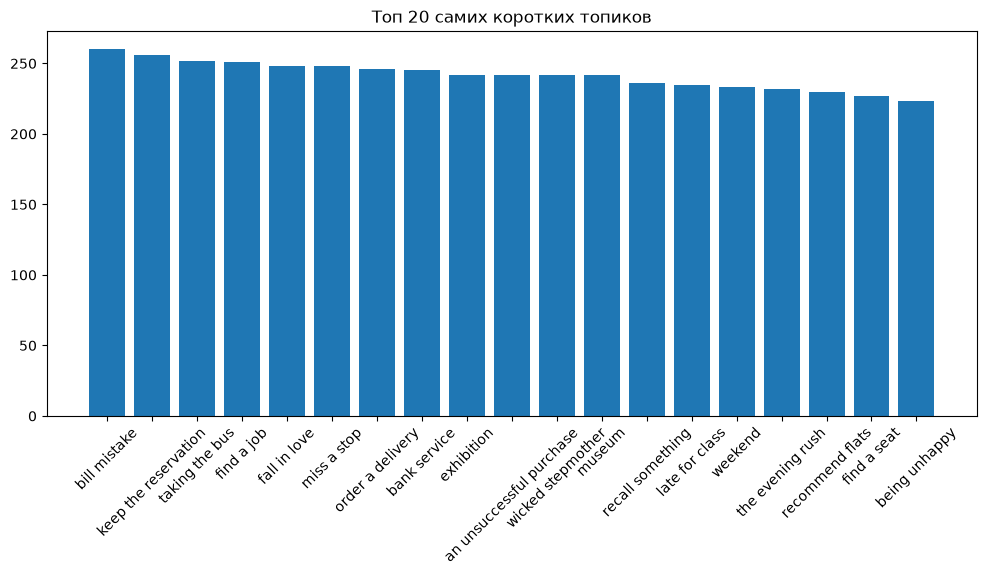

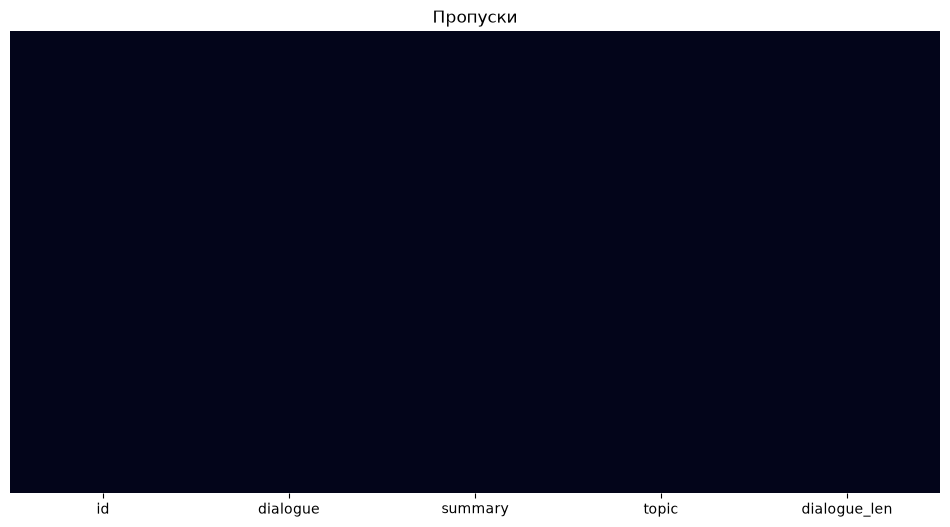

Общее количество уникальных топиков: (455,)
Размер: (500, 5)


In [134]:
eda_report(df_validation)

<hr>

Вывод: наблюдается дисбаланс топиков текстов. Будем выстраивать стратегию обучения на основе этого факта. 